# Árvore de Decisão e Gradient Boosting para Classificar Churn

Nesta atividade são treinados e comparados dois algoritmos supervisionados, Árvore de Decisão e Gradient Boosting (XGBoost), para identificar quais clientes têm mais chance de dar churn (abandonar o plano) nos próximos 60 dias.

A base usada é a base transformada exportada na entrega 1 (`treino_tratado.csv` e `teste_tratado.csv`), que já está dividida em treino (70%) e teste (30%) de forma estratificada, com os nulos preenchidos e as categóricas codificadas. As variáveis numéricas estão na escala original, porque árvores não dependem de escala e assim as regras extraídas ficam em unidades reais (dias, reais, chamados).

O conjunto de teste só é usado na avaliação final. Todas as escolhas (hiperparâmetros, poda, limiar de decisão e variáveis) são feitas com validação cruzada estratificada de 5 folds no treino.

In [1]:
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner
from xgboost import XGBClassifier
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.model_selection import (StratifiedKFold, GridSearchCV, cross_validate,
                                     cross_val_predict, learning_curve, train_test_split)
from sklearn.metrics import (recall_score, precision_score, f1_score, fbeta_score, accuracy_score,
                             roc_auc_score, average_precision_score, precision_recall_curve,
                             roc_curve, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
%matplotlib inline

optuna.logging.set_verbosity(optuna.logging.WARNING)

# Cores dos gráficos (mesmas da entrega 1): azul = permanência (0), laranja = churn (1)
CORES = ['#3e7fb5', '#ed7d31']
SEED = 42

In [2]:
# Base transformada exportada na entrega 1
df_treino = pd.read_csv('./data/treino_tratado.csv')
df_teste = pd.read_csv('./data/teste_tratado.csv')

X_train = df_treino.drop(columns='churn')
y_train = df_treino['churn']
X_test = df_teste.drop(columns='churn')
y_test = df_teste['churn']
features = X_train.columns.tolist()

# A mesma divisão em 5 folds é usada em todas as buscas e comparações
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print(f"Treino: {len(X_train)} linhas | churn = {y_train.sum()} | prevalência = {y_train.mean():.2%}")
print(f"Teste:  {len(X_test)} linhas | churn = {y_test.sum()} | prevalência = {y_test.mean():.2%}")
print(f"Atributos ({len(features)}): {features}")

Treino: 3493 linhas | churn = 1240 | prevalência = 35.50%
Teste:  1497 linhas | churn = 532 | prevalência = 35.54%
Atributos (13): ['tempo_ativo_dias', 'mensalidade_rs', 'qtd_chamados', 'atrasos_6m', 'fibra_optica', 'debito_automatico', 'atrasos_6m_faltante', 'tipo_contrato_Anual', 'tipo_contrato_Bienal', 'tipo_contrato_Mensal', 'forma_pagamento_Boleto', 'forma_pagamento_Cartão', 'forma_pagamento_Pix']


### Escolha da métrica de otimização

O recall da classe churn é a métrica principal do problema, porque deixar passar um cliente que vai cancelar custa mais do que mandar uma oferta para quem ficaria. Mas o recall sozinho não serve para escolher hiperparâmetros: um modelo que marca todos os clientes como churn tem recall 1. Com a prevalência de 35,5% desta base, até o F1 e o F2 dão nota alta para esse modelo trivial.

In [3]:
# Modelo trivial: marca todos os clientes do treino como churn
tudo_churn = np.ones(len(y_train), dtype=int)

print(f"Recall:    {recall_score(y_train, tudo_churn):.3f}")
print(f"Precision: {precision_score(y_train, tudo_churn):.3f}")
print(f"F1:        {f1_score(y_train, tudo_churn):.3f}")
print(f"F2:        {fbeta_score(y_train, tudo_churn, beta=2):.3f}")

Recall:    1.000
Precision: 0.355
F1:        0.524
F2:        0.733


Por isso o trabalho foi dividido em duas etapas:

1. **Busca de hiperparâmetros otimizando a PR-AUC** (average precision). A PR-AUC mede se o modelo coloca os clientes que cancelam no topo da lista de risco, olhando para a classe churn e sem depender de um limiar. O modelo trivial tem PR-AUC igual à prevalência (0,355), então ele não engana essa métrica.
2. **Escolha do limiar de decisão por uma meta de recall.** Depois de escolhido o modelo, o limiar é ajustado (com probabilidades de validação cruzada no treino) para capturar pelo menos 75% dos churns com a maior precision possível.

Assim o recall continua sendo a métrica principal do resultado, e a precision mostra o custo de alcançá-lo (quantas ofertas vão para clientes que não cancelariam).

In [4]:
# Métricas da validação cruzada (recall e precision usam o limiar padrão de 0,5)
METRICAS_CV = {'PR-AUC': 'average_precision', 'ROC-AUC': 'roc_auc',
               'Recall': 'recall', 'Precision': 'precision'}


def avaliar_cv(modelo, X=X_train, y=y_train):
    # Média de cada métrica nos folds de validação e a PR-AUC nos folds de treino, para medir o gap
    r = cross_validate(modelo, X, y, cv=skf, scoring=METRICAS_CV, return_train_score=True, n_jobs=-1)
    resultado = {f'{m} CV': r[f'test_{m}'].mean() for m in METRICAS_CV}
    resultado['PR-AUC treino'] = r['train_PR-AUC'].mean()
    resultado['Gap PR-AUC'] = resultado['PR-AUC treino'] - resultado['PR-AUC CV']
    return pd.Series(resultado)


def metricas(y, prob, limiar=0.5):
    # Métricas de um conjunto a partir das probabilidades e de um limiar de decisão
    pred = (prob >= limiar).astype(int)
    return {'Limiar': limiar,
            'Recall': recall_score(y, pred),
            'Precision': precision_score(y, pred, zero_division=0),
            'F1': f1_score(y, pred),
            'Accuracy': accuracy_score(y, pred),
            'ROC-AUC': roc_auc_score(y, prob),
            'PR-AUC': average_precision_score(y, prob),
            '% contatados': pred.mean()}


def comparar_variante(base, variante, X=X_train, y=y_train):
    # Diferença pareada de PR-AUC por fold (variante - base) e o erro padrão dessa diferença
    nota_base = cross_validate(base, X, y, cv=skf, scoring='average_precision', n_jobs=-1)['test_score']
    nota_var = cross_validate(variante, X, y, cv=skf, scoring='average_precision', n_jobs=-1)['test_score']
    diferenca = nota_var - nota_base
    return nota_var.mean(), diferenca.mean(), diferenca.std(ddof=1) / np.sqrt(len(diferenca))

### Baseline

Árvore de decisão com os parâmetros padrão do scikit-learn (sem nenhuma poda). Serve como piso de desempenho e mostra o tamanho que a árvore atinge quando cresce sem limite.

In [5]:
baseline = DecisionTreeClassifier(random_state=SEED)
res_baseline = avaliar_cv(baseline)
baseline.fit(X_train, y_train)

print(f"Folhas: {baseline.get_n_leaves()} | profundidade: {baseline.get_depth()}")
display(res_baseline.to_frame('Baseline').T.round(4))

Folhas: 942 | profundidade: 23


,PR-AUC CV,ROC-AUC CV,Recall CV,Precision CV,PR-AUC treino,Gap PR-AUC
Baseline,0.423,0.6065,0.4919,0.4929,1.0,0.577


Sem nenhuma poda, a árvore cresce até 942 folhas e profundidade 23. A PR-AUC é 1,0 nos folds de treino e 0,42 na validação: a árvore decorou o treino e quase não ordena os clientes por risco (ROC-AUC de 0,61). Esse é o piso que os modelos podados precisam superar.

## Árvore de Decisão

### Pré-poda (GridSearchCV)

Na pré-poda a árvore para de crescer antes de decorar o treino. As faixas da grade foram definidas assim:

- **max_depth (3 a 10 e sem limite):** 3 e 4 geram árvores fáceis de explicar; 8, 10 e sem limite mostram a partir de quando a árvore passa a decorar o treino (a baseline chega a profundidade acima de 20).
- **min_samples_leaf (1 a 100):** com 3.493 clientes no treino, uma folha de 100 clientes tem cerca de 3% da base. Folhas com poucos clientes geram taxas de churn instáveis. Em um teste preliminar com a faixa de 1 a 50, o melhor valor ficou no limite (50), por isso a faixa foi estendida até 100.
- **min_samples_split (2 e 50):** número mínimo de clientes em um nó para que ele seja dividido.
- **max_leaf_nodes (sem limite, 20 e 40):** limita o número de regras finais.
- **min_impurity_decrease (0 e 0,001):** ganho mínimo de impureza para aceitar uma divisão. Valores maiores, como 0,01, deixam a árvore com apenas 3 folhas nesta base.
- **criterion (gini e entropy).**
- **class_weight (nenhum e balanced):** não está na lista dos slides. Dá peso maior aos clientes de churn (35,5% da base) na hora de escolher as divisões.

São 7 × 2 × 6 × 2 × 3 × 2 × 2 = 2.016 combinações, cada uma avaliada em 5 folds.

In [6]:
grade_ad = {
    'max_depth': [3, 4, 5, 6, 8, 10, None],
    'min_samples_split': [2, 50],
    'min_samples_leaf': [1, 10, 25, 50, 75, 100],
    'criterion': ['gini', 'entropy'],
    'max_leaf_nodes': [None, 20, 40],
    'min_impurity_decrease': [0.0, 0.001],
    'class_weight': [None, 'balanced'],
}

inicio = time.time()
busca_ad = GridSearchCV(DecisionTreeClassifier(random_state=SEED), grade_ad, cv=skf,
                        scoring='average_precision', n_jobs=-1)
busca_ad.fit(X_train, y_train)
ad_prepoda = busca_ad.best_estimator_

print(f"Combinações testadas: {len(busca_ad.cv_results_['params'])} | tempo: {time.time() - inicio:.0f} s")
print(f"PR-AUC CV: {busca_ad.best_score_:.4f}")
print(f"Melhores parâmetros: {busca_ad.best_params_}")
print(f"Folhas: {ad_prepoda.get_n_leaves()} | profundidade: {ad_prepoda.get_depth()}")

Combinações testadas: 2016 | tempo: 582 s
PR-AUC CV: 0.6131
Melhores parâmetros: {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 8, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 50, 'min_samples_split': 2}
Folhas: 52 | profundidade: 8


,max_depth,min_samples_split,min_samples_leaf,criterion,max_leaf_nodes,min_impurity_decrease,class_weight,PR-AUC CV,desvio
1950,None,2,50,entropy,None,0.0,balanced,0.6131,0.0164
1951,None,50,50,entropy,None,0.0,balanced,0.6131,0.0164
1879,10,50,50,entropy,None,0.0,balanced,0.6131,0.0164
1878,10,2,50,entropy,None,0.0,balanced,0.6131,0.0164
1806,8,2,50,entropy,None,0.0,balanced,0.6131,0.0164
1807,8,50,50,entropy,None,0.0,balanced,0.6131,0.0164
1999,None,50,50,entropy,40,0.0,balanced,0.6126,0.0164
1998,None,2,50,entropy,40,0.0,balanced,0.6126,0.0164
1855,8,50,50,entropy,40,0.0,balanced,0.6126,0.0164
1854,8,2,50,entropy,40,0.0,balanced,0.6126,0.0164


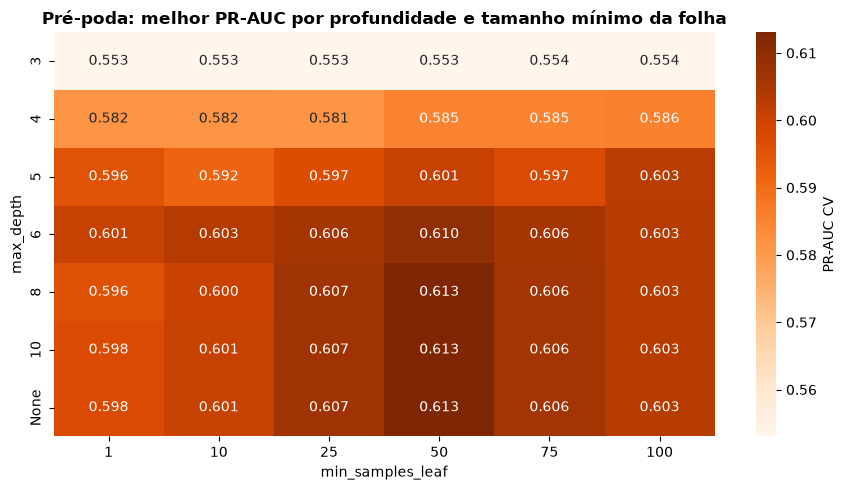

In [7]:
# As 10 melhores combinações da grade
ranking_ad = pd.DataFrame(busca_ad.cv_results_)
colunas_param = [f'param_{p}' for p in grade_ad]
top_ad = ranking_ad.sort_values('rank_test_score')[colunas_param + ['mean_test_score', 'std_test_score']].head(10)
top_ad.columns = list(grade_ad) + ['PR-AUC CV', 'desvio']
display(top_ad.round(4))

# Melhor PR-AUC encontrada para cada par (max_depth, min_samples_leaf), considerando os outros parâmetros
ranking_ad['max_depth'] = ranking_ad['param_max_depth'].map(lambda v: 'None' if v is None or pd.isna(v) else str(int(v)))
ranking_ad['min_samples_leaf'] = ranking_ad['param_min_samples_leaf'].astype(int)
mapa = ranking_ad.pivot_table(index='max_depth', columns='min_samples_leaf', values='mean_test_score', aggfunc='max')
mapa = mapa.loc[['3', '4', '5', '6', '8', '10', 'None']]

plt.figure(figsize=(9, 5))
sns.heatmap(mapa, annot=True, fmt='.3f', cmap='Oranges', cbar_kws={'label': 'PR-AUC CV'})
plt.title('Pré-poda: melhor PR-AUC por profundidade e tamanho mínimo da folha', fontweight='bold')
plt.ylabel('max_depth')
plt.xlabel('min_samples_leaf')
plt.tight_layout()
plt.show()

**Conclusão:**

- A melhor árvore usa `class_weight='balanced'`, `criterion='entropy'`, `max_depth=8` e `min_samples_leaf=50`, com 52 folhas e PR-AUC de 0,613 na validação cruzada. Com a grade estendida, o melhor `min_samples_leaf` (50) ficou no meio da faixa testada, e não mais no limite.
- O mapa mostra que a profundidade é o que mais pesa: árvores de profundidade 3 ficam em 0,553 e a PR-AUC sobe até a profundidade 6–8. Depois disso a profundidade deixa de importar, porque o mínimo de 50 clientes por folha já para o crescimento da árvore. É por isso que as configurações com profundidade 8, 10 e sem limite empatam no topo do ranking.
- O `class_weight='balanced'` aparece em todas as 10 melhores combinações. Dar mais peso aos clientes de churn muda as divisões escolhidas, e não só o limiar.

### Pós-poda (cost-complexity pruning)

Na pós-poda a árvore cresce inteira e depois os ramos que menos reduzem a impureza são cortados. Quanto maior o `ccp_alpha`, mais ramos são removidos. O scikit-learn calcula todos os valores de alpha em que a árvore muda (`cost_complexity_pruning_path`), e cada um é avaliado com validação cruzada. O caminho é calculado com e sem `class_weight='balanced'`.

Para escolher o alpha foi usada a **regra de 1 erro padrão**: entre os valores com PR-AUC até 1 erro padrão abaixo do melhor, fica o maior alpha (a árvore mais simples). Diferenças menores que o erro padrão não são confiáveis com 5 folds, então a árvore menor é preferida.

In [8]:
resultados_ccp = []
for cw in [None, 'balanced']:
    caminho = DecisionTreeClassifier(random_state=SEED, class_weight=cw).cost_complexity_pruning_path(X_train, y_train)
    for alpha in caminho.ccp_alphas[:-1]:  # o último alpha deixa a árvore só com a raiz
        arvore = DecisionTreeClassifier(random_state=SEED, class_weight=cw, ccp_alpha=alpha)
        r = cross_validate(arvore, X_train, y_train, cv=skf, scoring='average_precision', return_train_score=True)
        resultados_ccp.append({'class_weight': str(cw), 'ccp_alpha': alpha,
                               'PR-AUC CV': r['test_score'].mean(), 'desvio': r['test_score'].std(),
                               'PR-AUC treino': r['train_score'].mean(),
                               'folhas': arvore.fit(X_train, y_train).get_n_leaves()})
resultados_ccp = pd.DataFrame(resultados_ccp)

# Regra de 1 erro padrão
melhor_ccp = resultados_ccp.loc[resultados_ccp['PR-AUC CV'].idxmax()]
erro_padrao = melhor_ccp['desvio'] / np.sqrt(skf.get_n_splits())
mesmo_peso = resultados_ccp[resultados_ccp['class_weight'] == melhor_ccp['class_weight']]
candidatos = mesmo_peso[mesmo_peso['PR-AUC CV'] >= melhor_ccp['PR-AUC CV'] - erro_padrao]
escolhido_ccp = candidatos.loc[candidatos['ccp_alpha'].idxmax()]

cw_pospoda = None if escolhido_ccp['class_weight'] == 'None' else escolhido_ccp['class_weight']
ad_pospoda = DecisionTreeClassifier(random_state=SEED, class_weight=cw_pospoda,
                                    ccp_alpha=escolhido_ccp['ccp_alpha']).fit(X_train, y_train)

print(f"Alphas avaliados: {len(resultados_ccp)}")
print(f"Melhor alpha: {melhor_ccp['ccp_alpha']:.6f} (class_weight={melhor_ccp['class_weight']}) | "
      f"PR-AUC CV = {melhor_ccp['PR-AUC CV']:.4f} | folhas = {melhor_ccp['folhas']}")
print(f"Alpha escolhido (1 erro padrão): {escolhido_ccp['ccp_alpha']:.6f} | "
      f"PR-AUC CV = {escolhido_ccp['PR-AUC CV']:.4f} | folhas = {ad_pospoda.get_n_leaves()} | "
      f"profundidade = {ad_pospoda.get_depth()}")

Alphas avaliados: 911
Melhor alpha: 0.001956 (class_weight=None) | PR-AUC CV = 0.5872 | folhas = 10
Alpha escolhido (1 erro padrão): 0.001956 | PR-AUC CV = 0.5872 | folhas = 10 | profundidade = 5


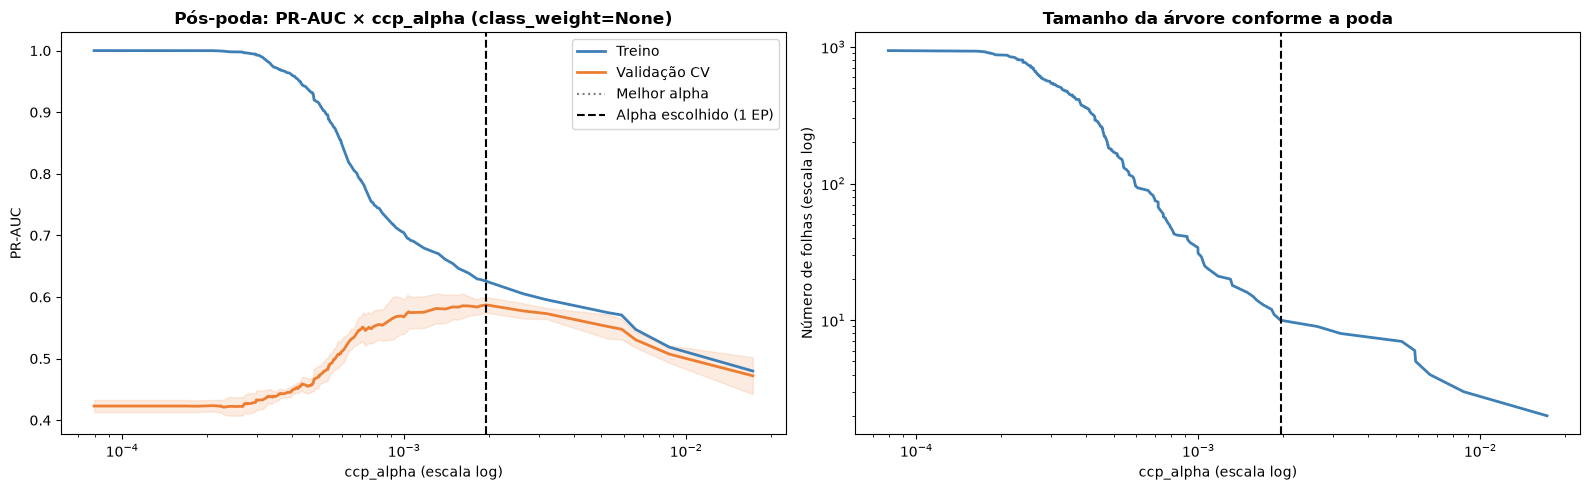

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
curva = mesmo_peso[mesmo_peso['ccp_alpha'] > 0]

axes[0].plot(curva['ccp_alpha'], curva['PR-AUC treino'], color=CORES[0], linewidth=2, label='Treino')
axes[0].plot(curva['ccp_alpha'], curva['PR-AUC CV'], color=CORES[1], linewidth=2, label='Validação CV')
axes[0].fill_between(curva['ccp_alpha'], curva['PR-AUC CV'] - curva['desvio'], curva['PR-AUC CV'] + curva['desvio'],
                     color=CORES[1], alpha=0.15)
axes[0].axvline(melhor_ccp['ccp_alpha'], color='gray', linestyle=':', label='Melhor alpha')
axes[0].axvline(escolhido_ccp['ccp_alpha'], color='black', linestyle='--', label='Alpha escolhido (1 EP)')
axes[0].set_xscale('log')
axes[0].set_xlabel('ccp_alpha (escala log)')
axes[0].set_ylabel('PR-AUC')
axes[0].set_title(f"Pós-poda: PR-AUC × ccp_alpha (class_weight={melhor_ccp['class_weight']})", fontweight='bold')
axes[0].legend()

axes[1].plot(curva['ccp_alpha'], curva['folhas'], color=CORES[0], linewidth=2)
axes[1].axvline(escolhido_ccp['ccp_alpha'], color='black', linestyle='--')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('ccp_alpha (escala log)')
axes[1].set_ylabel('Número de folhas (escala log)')
axes[1].set_title('Tamanho da árvore conforme a poda', fontweight='bold')

plt.tight_layout()
plt.show()

### Comparação: pré-poda vs. pós-poda

In [10]:
comparativo_ad = pd.DataFrame({
    'Baseline': res_baseline,
    'Pré-poda': avaliar_cv(ad_prepoda),
    'Pós-poda': avaliar_cv(ad_pospoda),
}).T
comparativo_ad['Folhas'] = [baseline.get_n_leaves(), ad_prepoda.get_n_leaves(), ad_pospoda.get_n_leaves()]
comparativo_ad['Profundidade'] = [baseline.get_depth(), ad_prepoda.get_depth(), ad_pospoda.get_depth()]
display(comparativo_ad.round(4))

# A árvore escolhida é a de maior PR-AUC na validação cruzada
if float(comparativo_ad.loc['Pré-poda', 'PR-AUC CV']) >= comparativo_ad.loc['Pós-poda', 'PR-AUC CV']:
    ad_escolhida, nome_ad = ad_prepoda, 'Pré-poda'
else:
    ad_escolhida, nome_ad = ad_pospoda, 'Pós-poda'
print(f"Árvore escolhida: {nome_ad}")

,PR-AUC CV,ROC-AUC CV,Recall CV,Precision CV,PR-AUC treino,Gap PR-AUC,Folhas,Profundidade
Baseline,0.4230,0.6065,0.4919,0.4929,1.0000,0.5770,942,23
Pré-poda,0.6131,0.7622,0.7048,0.5539,0.6713,0.0582,52,8
Pós-poda,0.5872,0.7498,0.4669,0.6283,0.6255,0.0383,10,5


Árvore escolhida: Pré-poda


**Conclusão:**

- As duas podas resolvem o overfitting da baseline: o gap de PR-AUC cai de 0,58 para 0,06 (pré-poda) e 0,04 (pós-poda).
- A pré-poda tem a maior PR-AUC (0,613 contra 0,587) e foi a árvore escolhida. A pós-poda gera uma árvore bem menor (10 folhas e profundidade 5) com uma perda pequena, então seria a opção se o objetivo principal fosse explicar o modelo em poucas regras.
- Pela regra de 1 erro padrão, nenhum alpha maior ficou perto o suficiente do melhor, então o alpha escolhido foi o próprio melhor. Na curva da pós-poda dá para ver as três fases: com alpha pequeno a árvore decora o treino (PR-AUC 1,0 no treino e 0,42 na validação), na faixa de 10⁻³ a validação atinge o máximo, e acima de 5×10⁻³ a árvore fica pequena demais e as duas curvas caem juntas (underfitting).
- O recall de 0,70 da pré-poda contra 0,47 da pós-poda, no limiar de 0,5, vem principalmente do `class_weight='balanced'`, que desloca as probabilidades para cima. Por isso a comparação entre modelos é feita pela PR-AUC, e o limiar é tratado à parte.

## Gradient Boosting (XGBoost)

### Otimização com Optuna

O Optuna usa o amostrador TPE (otimização bayesiana): cada nova tentativa é sorteada com mais chance nas regiões do espaço que deram bons resultados. O espaço de busca foi definido assim:

- **n_estimators (100 a 800) e learning_rate (0,01 a 0,3, escala log):** os dois se compensam, já que uma taxa menor precisa de mais árvores para chegar ao mesmo ponto. A escala log dá o mesmo peso para os intervalos 0,01–0,03 e 0,1–0,3.
- **max_depth (1 a 6):** no boosting cada árvore deve ser um aprendiz fraco. Profundidade 1 são tocos (sem interação entre variáveis). Em um teste preliminar com a faixa de 2 a 6, o melhor valor ficou no limite inferior, por isso a faixa começa em 1.
- **min_child_weight (1 a 20, escala log):** não está na lista dos slides. É o peso mínimo de amostras em uma folha, equivalente ao `min_samples_leaf` da árvore.
- **subsample (0,6 a 1) e colsample_bytree (0,5 a 1):** cada árvore usa uma amostra das linhas e das colunas, o que reduz a variância.
- **gamma (0 a 5):** ganho mínimo para fazer uma divisão (uma pré-poda dentro de cada árvore).
- **reg_alpha (0,001 a 10) e reg_lambda (0,1 a 20), escala log:** regularização L1 e L2 dos valores das folhas.
- **scale_pos_weight (1 a 3):** peso da classe churn. A razão não-churn/churn no treino é 1,82, e o limite de 3 permite testar pesos acima dela.

O **MedianPruner** interrompe tentativas ruins: depois de cada fold, a tentativa informa a PR-AUC média até ali (`trial.report`) e é cancelada se estiver abaixo da mediana das tentativas anteriores no mesmo fold. O número de tentativas é fixo (100, sem limite de tempo) para o resultado não depender da velocidade do computador.

In [11]:
XGB_FIXOS = {'random_state': SEED, 'n_jobs': -1, 'eval_metric': 'logloss', 'tree_method': 'hist'}


def objetivo(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 800, step=50),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'max_depth': trial.suggest_int('max_depth', 1, 6),
        'min_child_weight': trial.suggest_float('min_child_weight', 1, 20, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'gamma': trial.suggest_float('gamma', 0, 5),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 0.1, 20, log=True),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1.0, 3.0),
    }
    modelo = XGBClassifier(**params, **XGB_FIXOS)

    notas = []
    for passo, (idx_tr, idx_va) in enumerate(skf.split(X_train, y_train)):
        modelo.fit(X_train.iloc[idx_tr], y_train.iloc[idx_tr])
        prob = modelo.predict_proba(X_train.iloc[idx_va])[:, 1]
        notas.append(average_precision_score(y_train.iloc[idx_va], prob))
        trial.set_user_attr('folds', passo + 1)

        # Informa a média parcial e verifica se a tentativa deve ser interrompida
        trial.report(np.mean(notas), passo)
        if trial.should_prune():
            raise optuna.TrialPruned()
    return np.mean(notas)


estudo = optuna.create_study(direction='maximize', sampler=TPESampler(seed=SEED),
                             pruner=MedianPruner(n_startup_trials=10, n_warmup_steps=1))
inicio = time.time()
estudo.optimize(objetivo, n_trials=100)
tempo_optuna = time.time() - inicio

podadas = [t for t in estudo.trials if t.state == optuna.trial.TrialState.PRUNED]
fits_optuna = sum(t.user_attrs.get('folds', 0) for t in estudo.trials)
xgb_optuna = XGBClassifier(**estudo.best_params, **XGB_FIXOS)

print(f"Tentativas: {len(estudo.trials)} | interrompidas pelo pruner: {len(podadas)} | "
      f"treinos realizados: {fits_optuna} de {len(estudo.trials) * 5} | tempo: {tempo_optuna:.0f} s")
print(f"PR-AUC CV: {estudo.best_value:.4f}")
print("Melhores parâmetros:")
for nome, valor in estudo.best_params.items():
    print(f"  {nome}: {valor:.4f}" if isinstance(valor, float) else f"  {nome}: {valor}")

Tentativas: 100 | interrompidas pelo pruner: 61 | treinos realizados: 331 de 500 | tempo: 105 s
PR-AUC CV: 0.6655
Melhores parâmetros:
  n_estimators: 550
  learning_rate: 0.0282
  max_depth: 2
  min_child_weight: 1.0679
  subsample: 0.7568
  colsample_bytree: 0.9646
  gamma: 2.5786
  reg_alpha: 0.0260
  reg_lambda: 1.3932
  scale_pos_weight: 1.9085


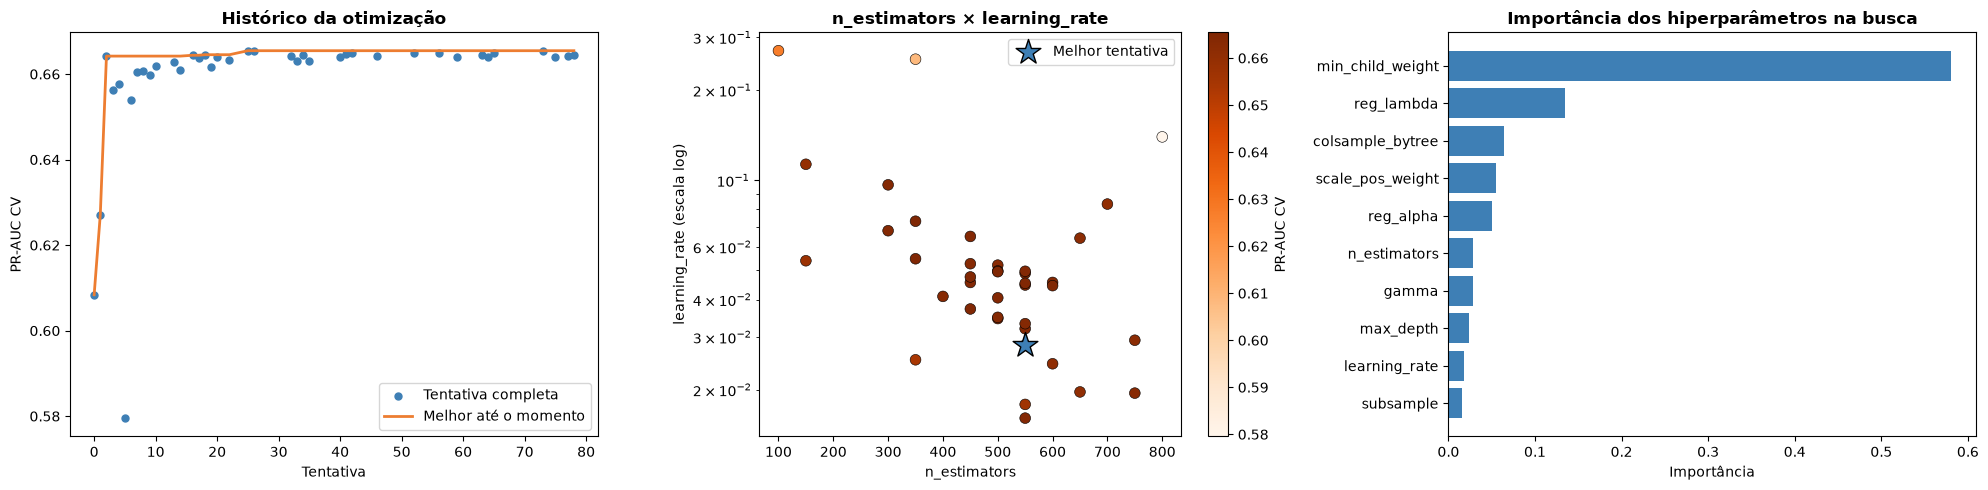

In [12]:
tentativas = estudo.trials_dataframe()
completas = tentativas[tentativas['state'] == 'COMPLETE']
importancia_params = pd.Series(optuna.importance.get_param_importances(estudo)).sort_values()

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Histórico da busca
axes[0].scatter(completas['number'], completas['value'], color=CORES[0], s=25, label='Tentativa completa')
axes[0].plot(completas['number'], completas['value'].cummax(), color=CORES[1], linewidth=2, label='Melhor até o momento')
axes[0].set_xlabel('Tentativa')
axes[0].set_ylabel('PR-AUC CV')
axes[0].set_title('Histórico da otimização', fontweight='bold')
axes[0].legend()

# Trade-off n_estimators × learning_rate
pontos = axes[1].scatter(completas['params_n_estimators'], completas['params_learning_rate'], c=completas['value'],
                         cmap='Oranges', edgecolors='k', linewidths=0.4, s=60)
axes[1].scatter(estudo.best_params['n_estimators'], estudo.best_params['learning_rate'], marker='*', s=350,
                color=CORES[0], edgecolors='k', label='Melhor tentativa')
axes[1].set_yscale('log')
axes[1].set_xlabel('n_estimators')
axes[1].set_ylabel('learning_rate (escala log)')
axes[1].set_title('n_estimators × learning_rate', fontweight='bold')
axes[1].legend()
plt.colorbar(pontos, ax=axes[1], label='PR-AUC CV')

# Importância de cada hiperparâmetro para o resultado da busca (fANOVA)
axes[2].barh(importancia_params.index, importancia_params.values, color=CORES[0])
axes[2].set_xlabel('Importância')
axes[2].set_title('Importância dos hiperparâmetros na busca', fontweight='bold')

plt.tight_layout()
plt.show()

**Conclusão:**

- O melhor XGBoost tem PR-AUC de 0,666 na validação cruzada, bem acima da melhor árvore (0,613). A configuração é de árvores rasas (`max_depth=2`), taxa de aprendizado baixa (0,028) com 550 árvores, amostragem de linhas (0,76) e `scale_pos_weight` de 1,91, próximo da razão não-churn/churn (1,82).
- O pruner interrompeu 61 das 100 tentativas, então foram feitos 331 treinos em vez de 500 (34% a menos).
- No gráfico de `n_estimators × learning_rate`, as tentativas boas formam uma faixa: com taxa baixa elas usam mais árvores, e as tentativas com taxa acima de 0,1 e poucas árvores (ou taxa alta com muitas árvores) ficam com notas piores.
- A importância dos hiperparâmetros (fANOVA) aponta `min_child_weight` e `reg_lambda` como os que mais variaram a nota. Esse gráfico deve ser lido com cuidado: ele só usa as tentativas completas, que ficaram concentradas na região boa, porque o pruner cortou as ruins.

### Comparação com GridSearchCV

Para comparar os dois mecanismos de busca, foi rodada uma grade com os hiperparâmetros que costumam pesar mais no XGBoost. Os demais ficam no valor padrão.

In [13]:
grade_xgb = {
    'n_estimators': [300, 700],
    'learning_rate': [0.02, 0.1],
    'max_depth': [2, 3, 4],
    'min_child_weight': [1, 5],
    'scale_pos_weight': [1.0, 1.8],
}

inicio = time.time()
busca_xgb = GridSearchCV(XGBClassifier(**XGB_FIXOS), grade_xgb, cv=skf, scoring='average_precision')
busca_xgb.fit(X_train, y_train)
tempo_grid = time.time() - inicio
n_combinacoes = len(busca_xgb.cv_results_['params'])

comparativo_busca = pd.DataFrame({
    'GridSearchCV': {'Combinações': n_combinacoes, 'Treinos realizados': n_combinacoes * 5,
                     'Tempo (s)': tempo_grid, 'PR-AUC CV': busca_xgb.best_score_},
    'Optuna': {'Combinações': len(estudo.trials), 'Treinos realizados': fits_optuna,
               'Tempo (s)': tempo_optuna, 'PR-AUC CV': estudo.best_value},
}).T
display(comparativo_busca.round(4))
print(f"Melhores parâmetros da grade: {busca_xgb.best_params_}")

# O XGBoost escolhido é o de maior PR-AUC na validação cruzada (mesmos folds nas duas buscas)
if estudo.best_value >= busca_xgb.best_score_:
    xgb_escolhido, nome_xgb = xgb_optuna, 'Optuna'
else:
    xgb_escolhido, nome_xgb = busca_xgb.best_estimator_, 'GridSearchCV'
print(f"XGBoost escolhido: {nome_xgb}")

,Combinações,Treinos realizados,Tempo (s),PR-AUC CV
GridSearchCV,48.0,240.0,86.4153,0.6641
Optuna,100.0,331.0,104.6535,0.6655


Melhores parâmetros da grade: {'learning_rate': 0.02, 'max_depth': 2, 'min_child_weight': 1, 'n_estimators': 700, 'scale_pos_weight': 1.8}
XGBoost escolhido: Optuna


**Conclusão:** as duas buscas chegaram a resultados praticamente iguais (0,666 contra 0,664) e às mesmas conclusões: árvores de profundidade 2, taxa baixa e peso da classe churn perto de 1,8. A grade foi um pouco mais rápida, mas só porque foi montada depois de saber onde estavam os bons valores e cobre 5 hiperparâmetros com 2 ou 3 valores cada. O Optuna explorou 10 hiperparâmetros em faixas contínuas no mesmo tempo, o que não seria viável numa grade (com só 3 valores por hiperparâmetro seriam 59.049 combinações).

### Trade-off entre n_estimators e learning_rate

Para ver a relação entre as duas variáveis, o treino foi separado em 80% para ajuste e 20% para validação, e o XGBoost escolhido foi treinado com 1.500 árvores e diferentes taxas de aprendizado (os outros hiperparâmetros ficam iguais). A curva mostra a log loss na validação a cada árvore adicionada.

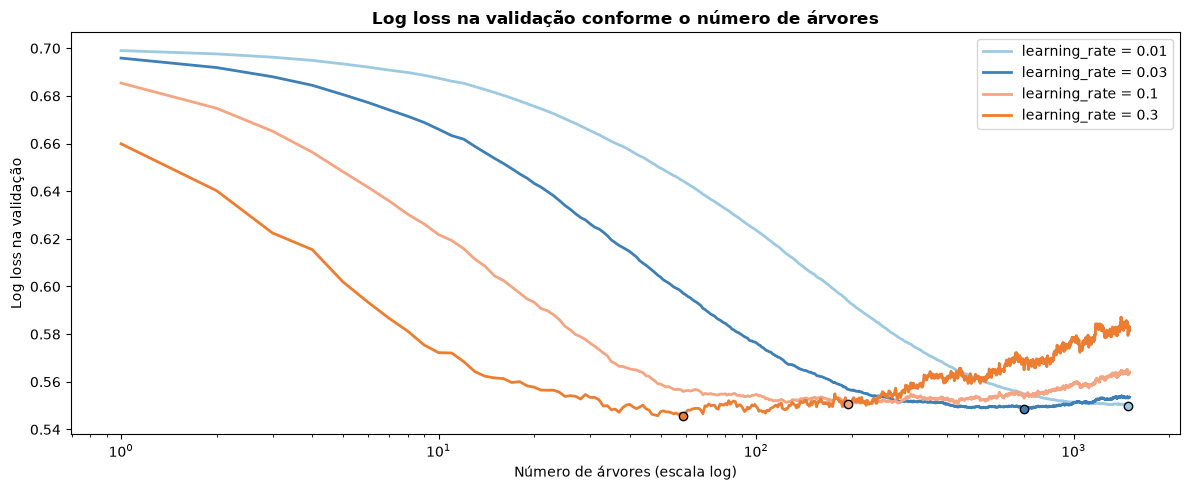

,learning_rate,Melhor nº de árvores,Log loss mínima,Log loss com 1.500 árvores
0,0.01,1487,0.5500,0.5501
1,0.03,698,0.5487,0.5536
2,0.10,194,0.5506,0.5641
3,0.30,59,0.5457,0.5829


In [14]:
X_aj, X_val, y_aj, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)

taxas = [0.01, 0.03, 0.1, 0.3]
cores_taxas = ['#9ecae1', CORES[0], '#f4a582', CORES[1]]
resumo_taxas = []

plt.figure(figsize=(12, 5))
for taxa, cor in zip(taxas, cores_taxas):
    modelo = clone(xgb_escolhido).set_params(learning_rate=taxa, n_estimators=1500)
    modelo.fit(X_aj, y_aj, eval_set=[(X_val, y_val)], verbose=False)
    perda = np.array(modelo.evals_result()['validation_0']['logloss'])
    melhor_it = int(perda.argmin()) + 1
    resumo_taxas.append({'learning_rate': taxa, 'Melhor nº de árvores': melhor_it,
                         'Log loss mínima': perda.min(), 'Log loss com 1.500 árvores': perda[-1]})
    plt.plot(np.arange(1, len(perda) + 1), perda, color=cor, linewidth=2, label=f'learning_rate = {taxa}')
    plt.scatter(melhor_it, perda.min(), color=cor, edgecolors='k', zorder=5)

plt.xscale('log')
plt.xlabel('Número de árvores (escala log)')
plt.ylabel('Log loss na validação')
plt.title('Log loss na validação conforme o número de árvores', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

display(pd.DataFrame(resumo_taxas).round(4))

**Conclusão:** as quatro taxas chegam a uma log loss mínima parecida (entre 0,546 e 0,551). O que muda é quantas árvores são necessárias e o que acontece depois do ponto ótimo. Com taxa 0,01 o modelo precisa de quase 1.500 árvores e a curva é estável. Com 0,03 o mínimo vem por volta de 700 árvores, próximo do que o Optuna escolheu. Com 0,3 o mínimo vem com 59 árvores, mas a perda sobe rápido em seguida e chega a 0,583 com 1.500 árvores: taxas altas tornam o número de árvores um parâmetro sensível, e um erro nele leva ao overfitting. Taxas baixas custam mais tempo de treino, mas são mais tolerantes.

## Hipóteses da equipe

Duas hipóteses foram testadas além do que os slides pedem. Uma variação só é adotada se o ganho médio de PR-AUC (diferença pareada fold a fold, nos mesmos 5 folds) for maior que o erro padrão dessa diferença.

### Hipótese 1: as variáveis criadas na entrega 1 ajudam os modelos?

Na entrega 1 foram criados os **bins preditivos** (cada variável numérica dividida em faixas por uma árvore rasa, com cada faixa recebendo a taxa de churn observada nela) e o **Combo Risco Triplo** (tempo ≤ 18 meses, chamados ≥ 2 e atrasos ≥ 1). Essas variáveis aumentaram a correlação com o churn na entrega 1.

Os bins usam o alvo, então calcular as faixas na base inteira antes da validação cruzada seria vazamento de dados. Por isso elas foram colocadas em um `Pipeline`: a cada fold, as faixas e as taxas são aprendidas só nos 4 folds de ajuste e aplicadas no fold de validação.

In [15]:
NUMERICAS = ['tempo_ativo_dias', 'mensalidade_rs', 'qtd_chamados', 'atrasos_6m']


class FeaturesEntrega1(BaseEstimator, TransformerMixin):
    # Adiciona os bins preditivos e o Combo Risco Triplo da entrega 1

    def __init__(self, usar_bins=True, usar_combo=True):
        self.usar_bins = usar_bins
        self.usar_combo = usar_combo

    def fit(self, X, y):
        self.cortes_, self.taxas_ = {}, {}
        self.media_ = float(np.mean(y))
        if self.usar_bins:
            for coluna in NUMERICAS:
                # Árvore rasa: no máximo 6 faixas, cada uma com pelo menos 5% dos clientes (mesma regra da entrega 1)
                arvore = DecisionTreeClassifier(max_leaf_nodes=6, min_samples_leaf=0.05, random_state=SEED)
                arvore.fit(X[[coluna]], y)
                cortes = sorted(t for t in arvore.tree_.threshold if t != -2)
                faixas = pd.cut(X[coluna], bins=[-np.inf] + cortes + [np.inf])
                self.cortes_[coluna] = cortes
                self.taxas_[coluna] = pd.Series(np.asarray(y), index=X.index).groupby(faixas, observed=True).mean()
        return self

    def transform(self, X):
        X = X.copy()
        for coluna, cortes in self.cortes_.items():
            faixas = pd.cut(X[coluna], bins=[-np.inf] + cortes + [np.inf])
            X[f'{coluna}_bin'] = faixas.map(self.taxas_[coluna]).astype(float).fillna(self.media_)
        if self.usar_combo:
            X['combo_risco_triplo'] = ((X['tempo_ativo_dias'] <= 18 * 30) & (X['qtd_chamados'] >= 2) &
                                       (X['atrasos_6m'] >= 1)).astype(int)
        return X


variantes = {'Só Combo Risco Triplo': (False, True), 'Só bins preditivos': (True, False), 'Bins + Combo': (True, True)}
linhas = []
for nome_modelo, modelo in [('Árvore de Decisão', ad_escolhida), ('XGBoost', xgb_escolhido)]:
    for nome_var, (bins, combo) in variantes.items():
        pipeline = Pipeline([('features', FeaturesEntrega1(bins, combo)), ('modelo', clone(modelo))])
        nota, ganho, ep = comparar_variante(modelo, pipeline)
        linhas.append({'Modelo': nome_modelo, 'Variante': nome_var, 'PR-AUC CV': nota,
                       'Ganho': ganho, 'Erro padrão': ep, 'Adotar': ganho > ep})
hipotese_1 = pd.DataFrame(linhas)
display(hipotese_1.round(4))

,Modelo,Variante,PR-AUC CV,Ganho,Erro padrão,Adotar
0,Árvore de Decisão,Só Combo Risco Triplo,0.6129,-0.0002,0.0024,False
1,Árvore de Decisão,Só bins preditivos,0.6097,-0.0034,0.0032,False
2,Árvore de Decisão,Bins + Combo,0.6075,-0.0056,0.0054,False
3,XGBoost,Só Combo Risco Triplo,0.6660,0.0005,0.0010,False
4,XGBoost,Só bins preditivos,0.6622,-0.0032,0.0018,False
5,XGBoost,Bins + Combo,0.6619,-0.0035,0.0017,False


**Conclusão:** a hipótese foi rejeitada. Nenhuma variante melhorou a PR-AUC além do erro padrão, e os bins pioraram um pouco os dois modelos. Isso faz sentido: os bins e o combo são cortes em variáveis que as próprias árvores já sabem cortar. A discretização aumentou a correlação de Pearson na entrega 1 porque a correlação só mede relação linear, mas uma árvore já encontra relações não lineares sozinha. Os modelos finais seguem com as variáveis originais.

### Hipótese 2: restrições monotônicas baseadas na análise da entrega 1

A análise da entrega 1 mostrou relações com direção clara: a taxa de churn cai conforme o tempo de cliente aumenta e sobe a cada chamado e a cada atraso. Tanto a árvore (`monotonic_cst`) quanto o XGBoost (`monotone_constraints`) permitem obrigar o modelo a respeitar essas direções. A hipótese é que isso reduz o ajuste ao ruído (por exemplo, uma faixa de tempo maior com risco maior só por acaso) e deixa as regras mais coerentes para o negócio. A mensalidade ficou sem restrição, porque a relação dela com o churn foi fraca na entrega 1.

In [16]:
sinais = {'tempo_ativo_dias': -1, 'qtd_chamados': 1, 'atrasos_6m': 1}
restricoes = [sinais.get(coluna, 0) for coluna in features]

ad_mono = clone(ad_escolhida).set_params(monotonic_cst=restricoes)
xgb_mono = clone(xgb_escolhido).set_params(monotone_constraints=tuple(restricoes))

linhas = []
for nome_modelo, base, variante in [('Árvore de Decisão', ad_escolhida, ad_mono), ('XGBoost', xgb_escolhido, xgb_mono)]:
    nota, ganho, ep = comparar_variante(base, variante)
    gap_base = avaliar_cv(base)['Gap PR-AUC']
    gap_var = avaliar_cv(variante)['Gap PR-AUC']
    linhas.append({'Modelo': nome_modelo, 'PR-AUC CV': nota, 'Ganho': ganho, 'Erro padrão': ep,
                   'Gap sem restrição': gap_base, 'Gap com restrição': gap_var, 'Adotar': ganho > ep})
hipotese_2 = pd.DataFrame(linhas).set_index('Modelo')
display(hipotese_2.round(4))

# Modelos finais
ad_final = ad_mono if hipotese_2.loc['Árvore de Decisão', 'Adotar'] else clone(ad_escolhida)
xgb_final = xgb_mono if hipotese_2.loc['XGBoost', 'Adotar'] else clone(xgb_escolhido)
ad_final.fit(X_train, y_train)
xgb_final.fit(X_train, y_train)

print(f"Árvore final: {nome_ad}{' + restrição monotônica' if hipotese_2.loc['Árvore de Decisão', 'Adotar'] else ''} | "
      f"folhas = {ad_final.get_n_leaves()} | profundidade = {ad_final.get_depth()}")
print(f"XGBoost final: {nome_xgb}{' + restrição monotônica' if hipotese_2.loc['XGBoost', 'Adotar'] else ''}")

,PR-AUC CV,Ganho,Erro padrão,Gap sem restrição,Gap com restrição,Adotar
Modelo,,,,,,
Árvore de Decisão,0.5818,-0.0312,0.0045,0.0582,0.0562,False
XGBoost,0.6677,0.0023,0.0011,0.0427,0.0378,True


Árvore final: Pré-poda | folhas = 52 | profundidade = 8
XGBoost final: Optuna + restrição monotônica


**Conclusão:**

- **XGBoost:** a restrição foi adotada. A PR-AUC subiu de 0,666 para 0,668 (ganho pequeno, mas acima do erro padrão) e o gap entre treino e validação caiu de 0,043 para 0,038. O modelo fica mais coerente com a análise da entrega 1 sem perder desempenho.
- **Árvore de Decisão:** a restrição foi rejeitada, com queda de 0,031 na PR-AUC. Na árvore a restrição é aplicada em cada divisão de forma gulosa e bloqueia combinações úteis, como quando um ramo de clientes mais antigos ainda tem risco alto por causa dos chamados. No XGBoost a restrição vale para a soma das árvores, o que dá mais liberdade ao modelo.

## Diagnóstico de overfitting

Para mostrar o efeito da complexidade no XGBoost, o modelo final é comparado com uma configuração profunda e com taxa de aprendizado alta (`max_depth=8`, `learning_rate=0.25`, 437 árvores). O gap é a diferença entre a PR-AUC nos folds de treino e nos folds de validação.

In [17]:
xgb_profundo = XGBClassifier(n_estimators=437, learning_rate=0.25, max_depth=8, **XGB_FIXOS)

diagnostico = pd.DataFrame({
    'AD final': avaliar_cv(ad_final),
    'XGBoost profundo (max_depth=8)': avaliar_cv(xgb_profundo),
    'XGBoost final': avaliar_cv(xgb_final),
}).T
display(diagnostico[['PR-AUC treino', 'PR-AUC CV', 'Gap PR-AUC', 'ROC-AUC CV']].round(4))

,PR-AUC treino,PR-AUC CV,Gap PR-AUC,ROC-AUC CV
AD final,0.6713,0.6131,0.0582,0.7622
XGBoost profundo (max_depth=8),1.0000,0.5755,0.4245,0.7224
XGBoost final,0.7055,0.6677,0.0378,0.7956


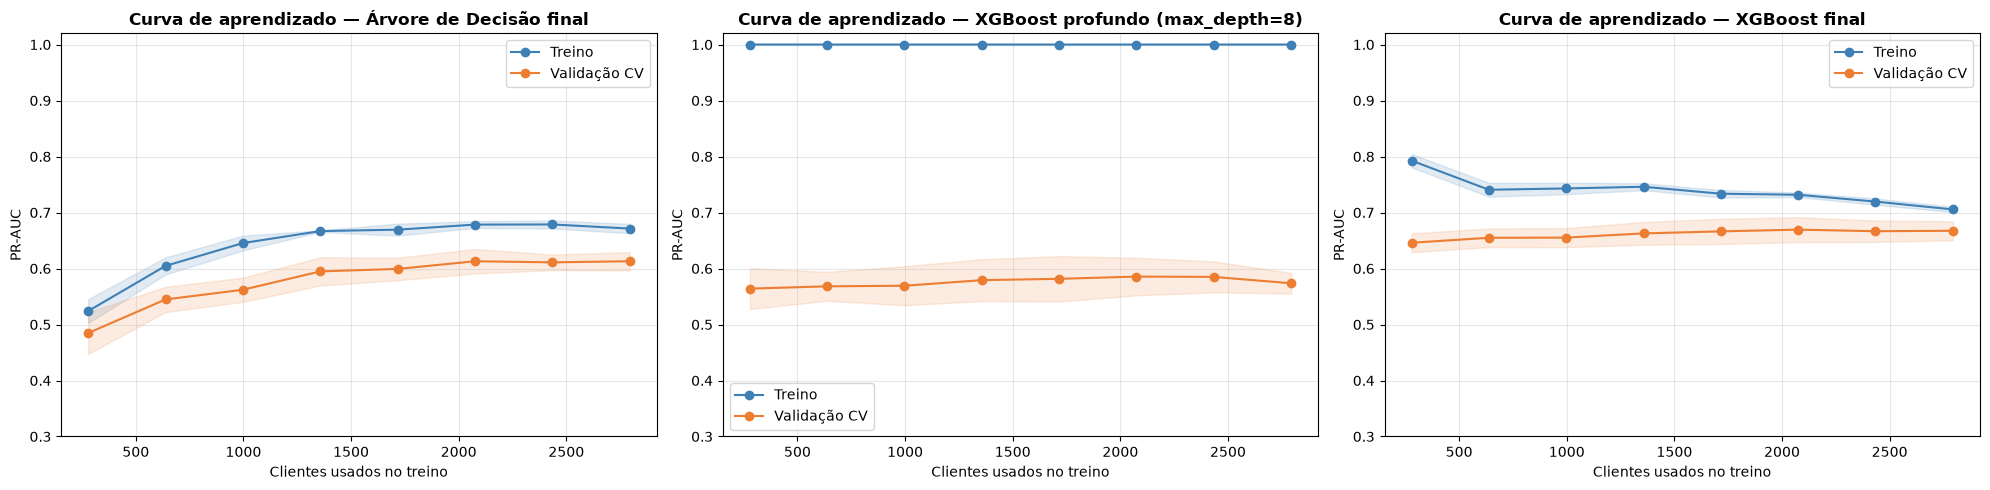

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, (modelo, titulo) in zip(axes, [(ad_final, 'Árvore de Decisão final'),
                                       (xgb_profundo, 'XGBoost profundo (max_depth=8)'),
                                       (xgb_final, 'XGBoost final')]):
    tamanhos, notas_tr, notas_va = learning_curve(modelo, X_train, y_train, cv=skf, scoring='average_precision',
                                                  train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1)
    for notas, cor, rotulo in [(notas_tr, CORES[0], 'Treino'), (notas_va, CORES[1], 'Validação CV')]:
        ax.plot(tamanhos, notas.mean(axis=1), 'o-', color=cor, label=rotulo)
        ax.fill_between(tamanhos, notas.mean(axis=1) - notas.std(axis=1), notas.mean(axis=1) + notas.std(axis=1),
                        color=cor, alpha=0.15)
    ax.set_ylim(0.3, 1.02)
    ax.set_title(f'Curva de aprendizado — {titulo}', fontweight='bold')
    ax.set_xlabel('Clientes usados no treino')
    ax.set_ylabel('PR-AUC')
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

**Conclusão:**

- O XGBoost profundo decora o treino: PR-AUC 1,0 no treino em qualquer tamanho de base e 0,58 na validação (gap de 0,42), pior até que a árvore de decisão. Mais complexidade não trouxe ganho nenhum nesta base.
- O XGBoost final tem gap de 0,038 e a maior PR-AUC de validação. Na curva de aprendizado as duas linhas vão se aproximando conforme entram mais clientes, e a validação fica estável no final: o modelo está bem ajustado, sem sinal de que esteja decorando o treino.
- A árvore final tem gap de 0,058. A curva de validação para de subir por volta de 2.000 clientes, o que indica que o limite dela é a própria capacidade de representação (52 folhas), e não a quantidade de dados.

## Escolha do limiar de decisão

O limiar padrão de 0,5 não tem nenhum significado especial para o negócio. Aqui ele é escolhido com as probabilidades **fora da amostra** do treino (`cross_val_predict`): cada cliente recebe a probabilidade de um modelo que não o viu no ajuste. O teste continua intocado.

A meta definida é capturar **pelo menos 75% dos churns** (recall ≥ 0,75). Entre os limiares que atingem a meta, fica o maior, que é o que dá a maior precision. A tabela mostra também outras metas, para deixar visível o custo de cada ponto de recall.

In [19]:
META_RECALL = 0.75
modelos_finais = {'Árvore de Decisão': ad_final, 'XGBoost': xgb_final}

# Probabilidades fora da amostra no treino
prob_oof = {nome: cross_val_predict(modelo, X_train, y_train, cv=skf, method='predict_proba')[:, 1]
            for nome, modelo in modelos_finais.items()}


def limiar_para_recall(y, prob, meta):
    # Maior limiar que ainda atinge o recall da meta
    precisao, recall, limiares_pr = precision_recall_curve(y, prob)
    i = np.where(recall[:-1] >= meta)[0][-1]
    return limiares_pr[i], recall[i], precisao[i]


linhas = []
for nome, prob in prob_oof.items():
    for meta in [0.60, 0.70, 0.75, 0.80, 0.85, 0.90]:
        limiar, rec, prec = limiar_para_recall(y_train, prob, meta)
        linhas.append({'Modelo': nome, 'Meta de recall': meta, 'Limiar': limiar, 'Recall CV': rec,
                       'Precision CV': prec, '% contatados': (prob >= limiar).mean()})
tabela_limiar = pd.DataFrame(linhas)
display(tabela_limiar.pivot(index='Meta de recall', columns='Modelo',
                            values=['Limiar', 'Recall CV', 'Precision CV', '% contatados']).round(3))

limiares = {nome: limiar_para_recall(y_train, prob, META_RECALL)[0] for nome, prob in prob_oof.items()}
for nome, limiar in limiares.items():
    print(f"Limiar escolhido — {nome}: {limiar:.3f}")

Limiar                   Recall CV                    \
Modelo         XGBoost Árvore de Decisão   XGBoost Árvore de Decisão   
Meta de recall                                                         
0.60             0.624             0.569      0.60             0.606   
0.70             0.550             0.514      0.70             0.705   
0.75             0.493             0.467      0.75             0.751   
0.80             0.448             0.429      0.80             0.801   
0.85             0.387             0.386      0.85             0.856   
0.90             0.324             0.326      0.90             0.902   

               Precision CV                   % contatados                    
Modelo              XGBoost Árvore de Decisão      XGBoost Árvore de Decisão  
Meta de recall                                                                
0.60                  0.637             0.579        0.334             0.372  
0.70                  0.599             0.554        0.415             0.452  
0.75                  0.566             0.527        0.471             0.506  
0.80                  0.547             0.513        0.519             0.554  
0.85                  0.524             0.492        0.576             0.618  
0.90                  0.495             0.474        0.645             0.675

Limiar escolhido — Árvore de Decisão: 0.467
Limiar escolhido — XGBoost: 0.493


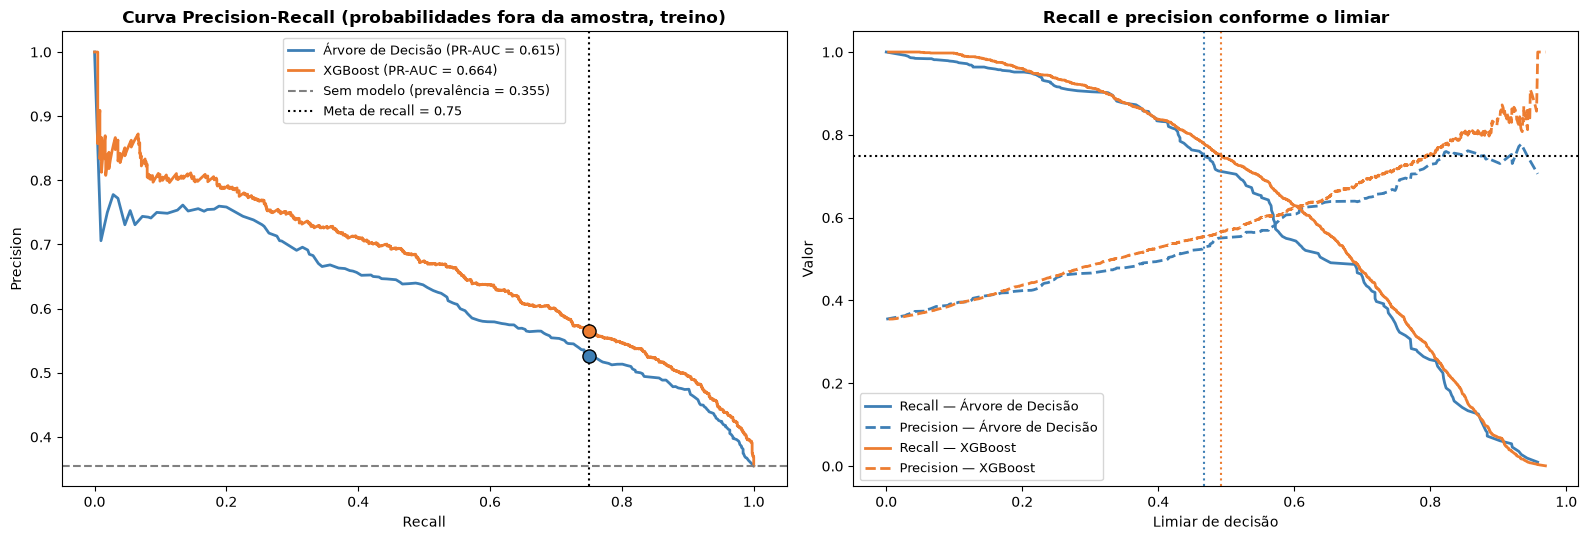

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
cores_modelos = {'Árvore de Decisão': CORES[0], 'XGBoost': CORES[1]}

for nome, prob in prob_oof.items():
    precisao, recall, limiares_pr = precision_recall_curve(y_train, prob)
    cor = cores_modelos[nome]
    axes[0].plot(recall, precisao, color=cor, linewidth=2,
                 label=f'{nome} (PR-AUC = {average_precision_score(y_train, prob):.3f})')
    pred = prob >= limiares[nome]
    axes[0].scatter(recall_score(y_train, pred), precision_score(y_train, pred), color=cor, edgecolors='k', s=90, zorder=5)

    axes[1].plot(limiares_pr, recall[:-1], color=cor, linewidth=2, label=f'Recall — {nome}')
    axes[1].plot(limiares_pr, precisao[:-1], color=cor, linewidth=2, linestyle='--', label=f'Precision — {nome}')
    axes[1].axvline(limiares[nome], color=cor, linestyle=':')

axes[0].axhline(y_train.mean(), color='gray', linestyle='--', label=f'Sem modelo (prevalência = {y_train.mean():.3f})')
axes[0].axvline(META_RECALL, color='black', linestyle=':', label=f'Meta de recall = {META_RECALL}')
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].set_title('Curva Precision-Recall (probabilidades fora da amostra, treino)', fontweight='bold')
axes[0].legend(fontsize=9)

axes[1].axhline(META_RECALL, color='black', linestyle=':')
axes[1].set_xlabel('Limiar de decisão')
axes[1].set_ylabel('Valor')
axes[1].set_title('Recall e precision conforme o limiar', fontweight='bold')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

**Conclusão:**

- Para capturar 75% dos churns, o limiar fica em 0,493 no XGBoost e 0,467 na árvore. Nesse ponto o XGBoost tem precision de 0,566 e contata 47% da base, e a árvore tem precision de 0,527 e contata 51%. Para o mesmo recall, o XGBoost manda menos ofertas para clientes que não cancelariam.
- A tabela mostra o custo de cada ponto de recall: subir de 75% para 90% de recall no XGBoost faz a precision cair de 0,566 para 0,495 e aumenta a base contatada de 47% para 65%. A meta pode ser ajustada pela área de negócio conforme o custo de uma oferta de retenção e o valor de um cliente retido.
- Como o XGBoost usa `scale_pos_weight` perto de 1,9, as probabilidades dele já ficam deslocadas para cima, e o limiar escolhido ficou perto de 0,5. Na árvore com `class_weight='balanced'` acontece o mesmo. Sem o peso de classe, o limiar teria que ser bem mais baixo para atingir a mesma meta.

## Avaliação final no conjunto de teste

A partir daqui o teste é usado pela primeira vez. Nenhuma das métricas abaixo foi usada para escolher modelo, hiperparâmetro ou limiar: elas só mostram o desempenho esperado em clientes novos.

In [21]:
prob_teste = {nome: modelo.predict_proba(X_test)[:, 1] for nome, modelo in modelos_finais.items()}

avaliacao = pd.DataFrame({
    'Sem modelo (todos churn)': metricas(y_test, np.ones(len(y_test))),
    'Baseline (limiar 0,5)': metricas(y_test, baseline.predict_proba(X_test)[:, 1]),
    'AD pré-poda (limiar 0,5)': metricas(y_test, ad_prepoda.predict_proba(X_test)[:, 1]),
    'AD pós-poda (limiar 0,5)': metricas(y_test, ad_pospoda.predict_proba(X_test)[:, 1]),
    'AD final (limiar ajustado)': metricas(y_test, prob_teste['Árvore de Decisão'], limiares['Árvore de Decisão']),
    'XGBoost final (limiar 0,5)': metricas(y_test, prob_teste['XGBoost']),
    'XGBoost final (limiar ajustado)': metricas(y_test, prob_teste['XGBoost'], limiares['XGBoost']),
}).T
display(avaliacao.round(4))

,Limiar,Recall,Precision,F1,Accuracy,ROC-AUC,PR-AUC,% contatados
Sem modelo (todos churn),0.5000,1.0000,0.3554,0.5244,0.3554,0.5000,0.3554,1.0000
"Baseline (limiar 0,5)",0.5000,0.5301,0.5361,0.5331,0.6700,0.6386,0.4512,0.3514
"AD pré-poda (limiar 0,5)",0.5000,0.6955,0.5362,0.6056,0.6780,0.7559,0.6207,0.4609
"AD pós-poda (limiar 0,5)",0.5000,0.4286,0.6387,0.5129,0.7108,0.7368,0.5899,0.2385
AD final (limiar ajustado),0.4669,0.7068,0.5179,0.5978,0.6620,0.7559,0.6207,0.4850
"XGBoost final (limiar 0,5)",0.5000,0.7350,0.5691,0.6415,0.7081,0.7927,0.6766,0.4589
XGBoost final (limiar ajustado),0.4925,0.7350,0.5658,0.6394,0.7054,0.7927,0.6766,0.4616


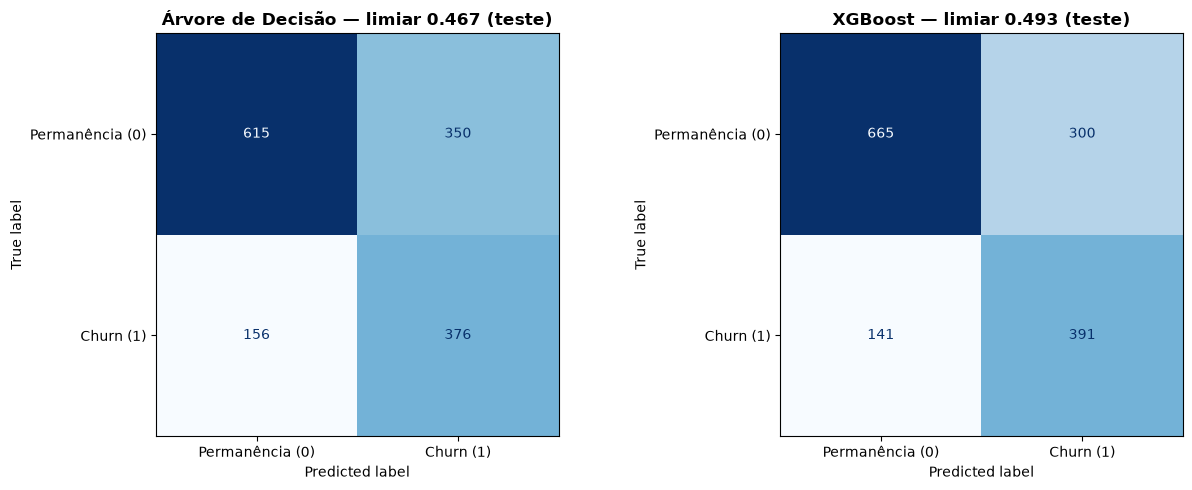

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (nome, prob) in zip(axes, prob_teste.items()):
    pred = (prob >= limiares[nome]).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['Permanência (0)', 'Churn (1)'],
                                            cmap='Blues', values_format='d', ax=ax, colorbar=False)
    ax.set_title(f'{nome} — limiar {limiares[nome]:.3f} (teste)', fontweight='bold')
plt.tight_layout()
plt.show()

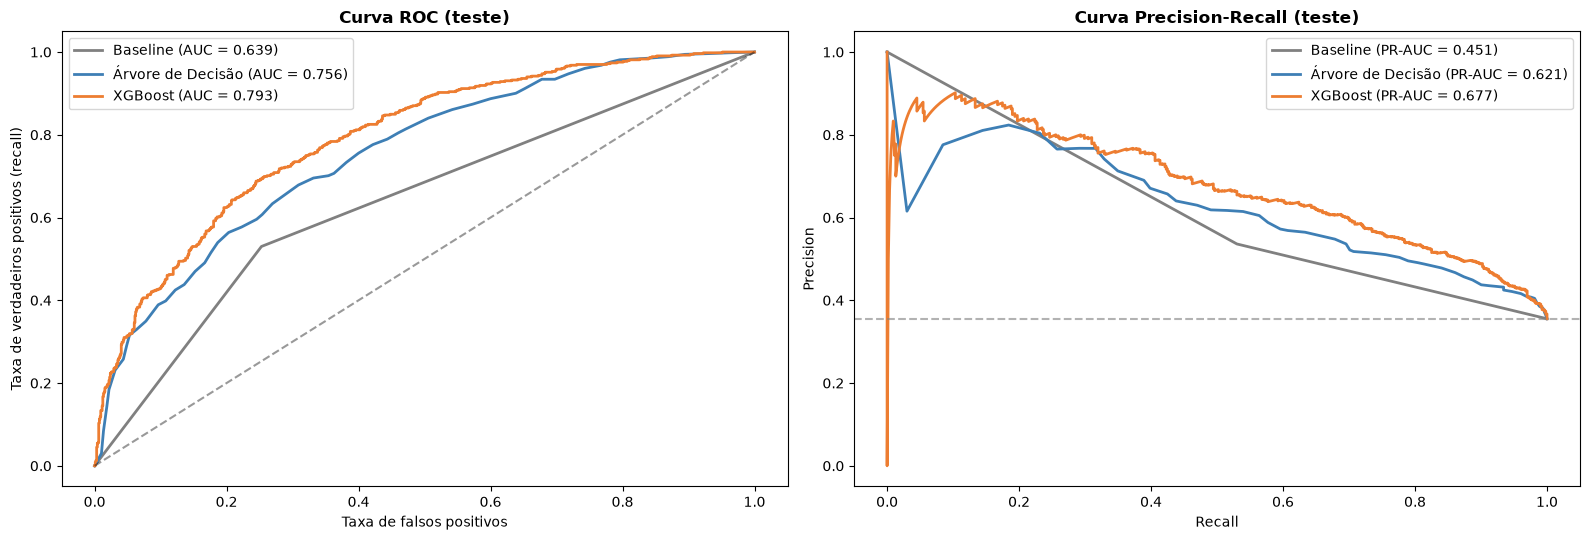

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
curvas = [('Baseline', baseline.predict_proba(X_test)[:, 1], 'gray')] + \
         [(nome, prob, cores_modelos[nome]) for nome, prob in prob_teste.items()]

for nome, prob, cor in curvas:
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[0].plot(fpr, tpr, color=cor, linewidth=2, label=f'{nome} (AUC = {roc_auc_score(y_test, prob):.3f})')
    precisao, recall, _ = precision_recall_curve(y_test, prob)
    axes[1].plot(recall, precisao, color=cor, linewidth=2,
                 label=f'{nome} (PR-AUC = {average_precision_score(y_test, prob):.3f})')

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.4)
axes[0].set_xlabel('Taxa de falsos positivos')
axes[0].set_ylabel('Taxa de verdadeiros positivos (recall)')
axes[0].set_title('Curva ROC (teste)', fontweight='bold')
axes[0].legend()

axes[1].axhline(y_test.mean(), color='gray', linestyle='--', alpha=0.6)
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Curva Precision-Recall (teste)', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

In [24]:
# Gap treino × teste com o limiar escolhido
linhas = {}
for nome, modelo in modelos_finais.items():
    m_tr = metricas(y_train, modelo.predict_proba(X_train)[:, 1], limiares[nome])
    m_te = metricas(y_test, prob_teste[nome], limiares[nome])
    for metrica in ['Recall', 'Precision', 'ROC-AUC', 'PR-AUC']:
        linhas[(nome, metrica)] = {'Treino': m_tr[metrica], 'Teste': m_te[metrica], 'Gap': m_tr[metrica] - m_te[metrica]}
gap_final = pd.DataFrame(linhas).T
display(gap_final.round(4))

Treino   Teste     Gap
Árvore de Decisão Recall     0.7815  0.7068  0.0747
                  Precision  0.5650  0.5179  0.0471
                  ROC-AUC    0.8056  0.7559  0.0497
                  PR-AUC     0.6790  0.6207  0.0584
XGBoost           Recall     0.7855  0.7350  0.0505
                  Precision  0.5889  0.5658  0.0230
                  ROC-AUC    0.8217  0.7927  0.0290
                  PR-AUC     0.7010  0.6766  0.0244

**Conclusão:**

- No teste, o XGBoost final atinge **recall de 0,735 com precision de 0,566**, e a árvore final atinge recall de 0,707 com precision de 0,518. Os dois ficam próximos da meta de 75% definida no treino, o que mostra que o limiar escolhido com validação cruzada se manteve em clientes novos.
- O XGBoost é melhor em todas as métricas de ordenação (ROC-AUC 0,793 contra 0,756 e PR-AUC 0,677 contra 0,621). A diferença entre os dois não vem mais do peso de classe, já que os dois foram otimizados com o mesmo critério e os dois podiam usar peso de classe.
- A árvore pós-poda, no limiar de 0,5, só encontra 43% dos churns, apesar de ter ROC-AUC de 0,737. O limiar é tão importante quanto o modelo: com um limiar mais baixo, a mesma árvore recuperaria boa parte desse recall.
- O modelo trivial (todos churn) tem recall 1,0 mas precision igual à prevalência (0,355) e acurácia de 0,355. A acurácia não é uma boa métrica aqui: a baseline tem acurácia de 0,67 e é o pior modelo de verdade.
- Os gaps entre treino e teste são pequenos (até 0,05 no XGBoost e até 0,075 na árvore). O XGBoost generaliza melhor que a árvore, e o resultado no teste ficou próximo do estimado pela validação cruzada (PR-AUC 0,668 na CV e 0,677 no teste), o que indica que não houve vazamento de dados.

## Interpretação dos modelos

### Regras extraídas da árvore final

As regras abaixo são os caminhos da árvore até a profundidade 3 (o topo da árvore). A taxa de churn de cada regra é a taxa real observada no treino entre os clientes que caem nela.

|--- tipo_contrato_Mensal <= 0.5
|   |--- tempo_ativo_dias <= 684.5
|   |   |--- fibra_optica <= 0.5
|   |   |   |--- atrasos_6m <= 1.5
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- atrasos_6m >  1.5
|   |   |   |   |--- class: 0
|   |   |--- fibra_optica >  0.5
|   |   |   |--- atrasos_6m <= 0.5
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- atrasos_6m >  0.5
|   |   |   |   |--- truncated branch of depth 3
|   |--- tempo_ativo_dias >  684.5
|   |   |--- tempo_ativo_dias <= 1294.0
|   |   |   |--- mensalidade_rs <= 77.1
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- mensalidade_rs >  77.1
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- tempo_ativo_dias >  1294.0
|   |   |   |--- mensalidade_rs <= 76.7
|   |   |   |   |--- class: 0
|   |   |   |--- mensalidade_rs >  76.7
|   |   |   |   |--- truncated branch of depth 2
|--- tipo_contrato_Mensal >  0.5
|   |--- tempo_ativo_dias <= 868.0
|   |   |--- qtd_chamados <= 

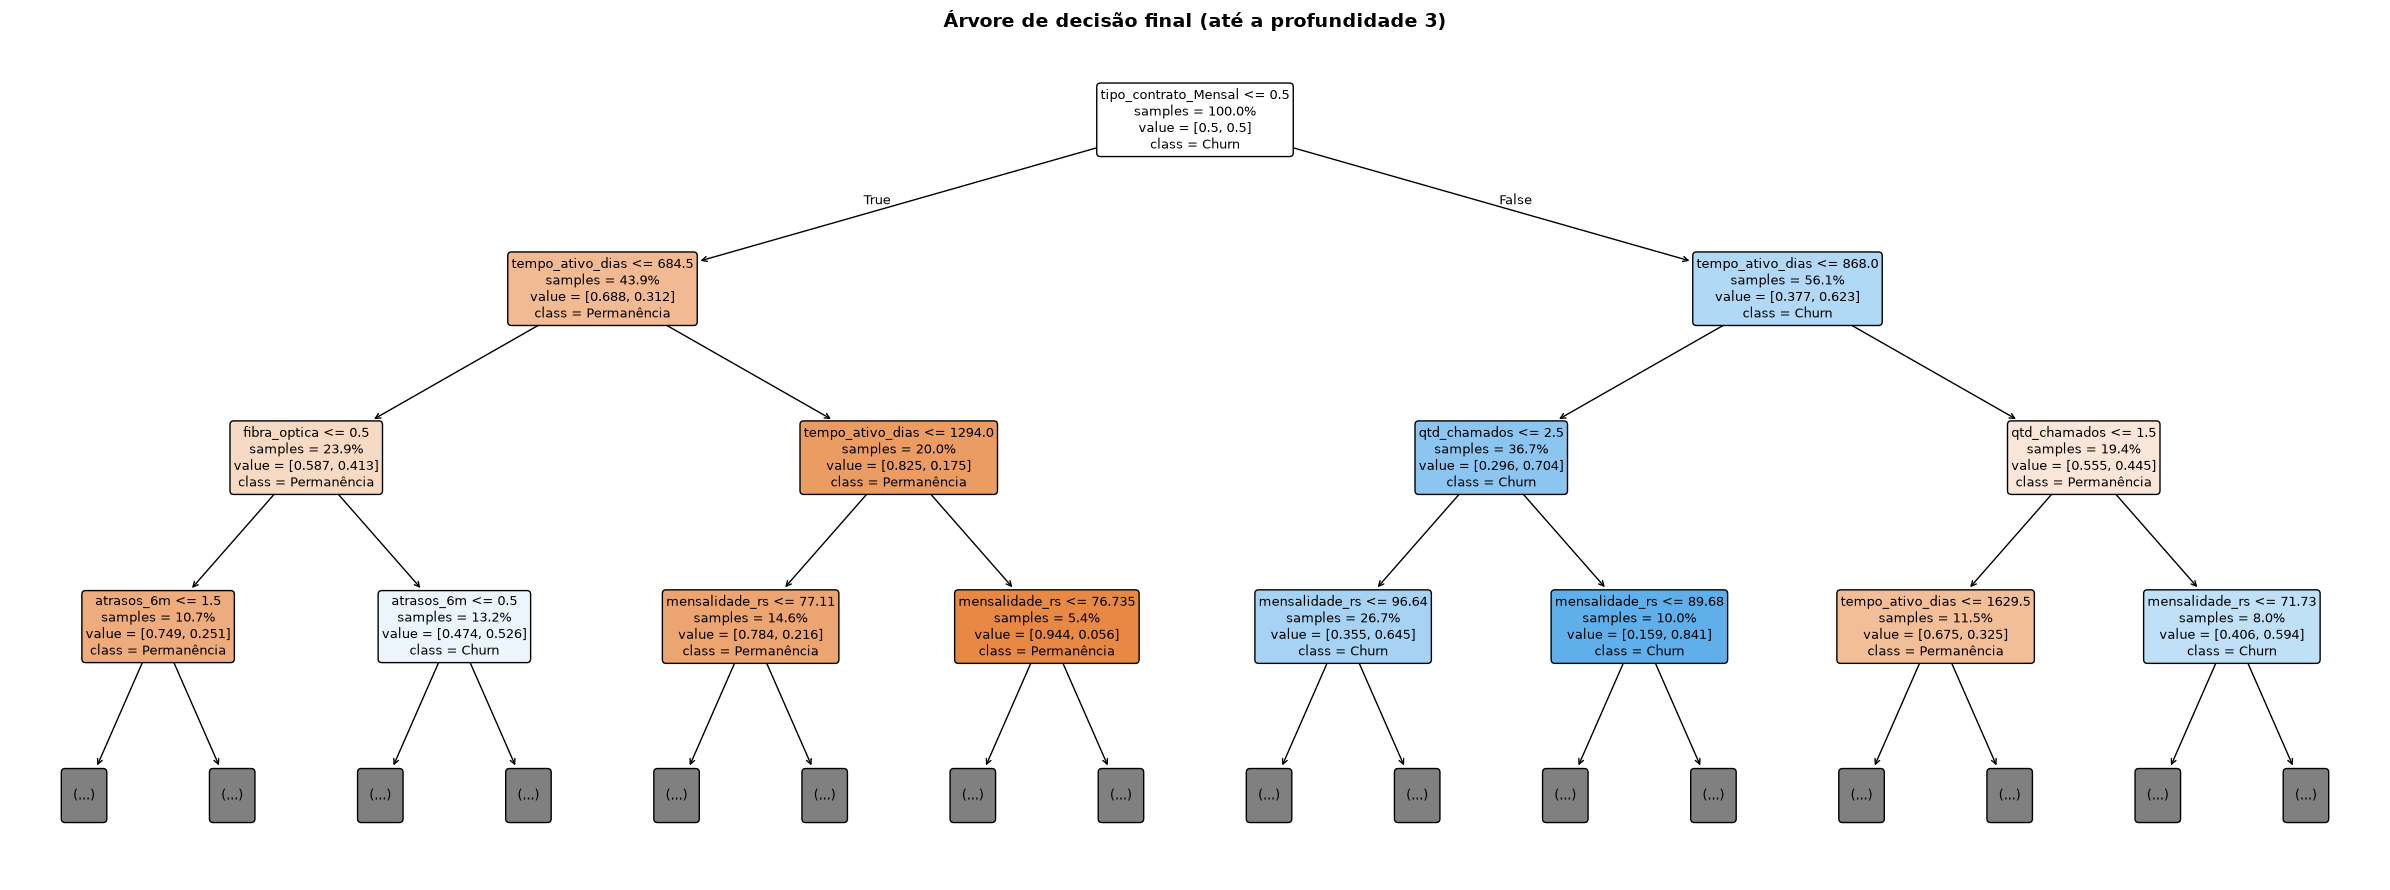

In [25]:
print(export_text(ad_final, feature_names=features, max_depth=3, decimals=1))

fig, ax = plt.subplots(figsize=(24, 9))
plot_tree(ad_final, max_depth=3, feature_names=features, class_names=['Permanência', 'Churn'],
          filled=True, rounded=True, fontsize=9, impurity=False, proportion=True, ax=ax)
ax.set_title('Árvore de decisão final (até a profundidade 3)', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

In [27]:
ONE_HOT = {'tipo_contrato_': 'contrato', 'forma_pagamento_': 'pagamento'}
BINARIAS = ['fibra_optica', 'debito_automatico', 'atrasos_6m_faltante']
INTEIRAS = ['tempo_ativo_dias', 'qtd_chamados', 'atrasos_6m']


def formatar_condicao(coluna, minimo, maximo):
    # Converte os cortes da árvore em condições legíveis (valores inteiros, categorias e reais)
    for prefixo, nome in ONE_HOT.items():
        if coluna.startswith(prefixo):
            return f"{nome} {'=' if minimo >= 0.5 else '≠'} {coluna[len(prefixo):]}"
    if coluna in BINARIAS:
        return f"{coluna} = {1 if minimo >= 0.5 else 0}"
    if coluna in INTEIRAS:
        a = None if minimo == -np.inf else int(np.floor(minimo)) + 1
        b = None if maximo == np.inf else int(np.floor(maximo))
        texto = (f'{a} ≤ {coluna} ≤ {b}' if a is not None and b is not None
                 else f'{coluna} ≥ {a}' if a is not None else f'{coluna} ≤ {b}')
        if coluna == 'tempo_ativo_dias':
            meses = [f'{v / 30:.0f}' for v in (a, b) if v is not None]
            texto += f" (≈ {' a '.join(meses)} meses)"
        return texto
    if minimo != -np.inf and maximo != np.inf:
        return f'R$ {minimo:.2f} < {coluna} ≤ R$ {maximo:.2f}'
    return f'{coluna} > R$ {minimo:.2f}' if minimo != -np.inf else f'{coluna} ≤ R$ {maximo:.2f}'


def extrair_regras(arvore, X, y, profundidade_max=None):
    t = arvore.tree_
    caminho = arvore.decision_path(X).toarray().astype(bool)
    regras = []

    def percorrer(no, limites, profundidade):
        folha = t.children_left[no] == -1
        if folha or profundidade == profundidade_max:
            regras.append((no, limites))
            return
        coluna, corte = X.columns[t.feature[no]], t.threshold[no]
        minimo, maximo = limites.get(coluna, (-np.inf, np.inf))
        percorrer(t.children_left[no], {**limites, coluna: (minimo, min(maximo, corte))}, profundidade + 1)
        percorrer(t.children_right[no], {**limites, coluna: (max(minimo, corte), maximo)}, profundidade + 1)

    percorrer(0, {}, 0)

    linhas = []
    for no, limites in regras:
        condicoes = [formatar_condicao(c, a, b) for c, (a, b) in limites.items()]
        # Se a regra já diz qual é a categoria (=), as condições de exclusão (≠) do mesmo grupo sobram
        for nome in ONE_HOT.values():
            if any(c.startswith(f'{nome} =') for c in condicoes):
                condicoes = [c for c in condicoes if not c.startswith(f'{nome} ≠')]
        clientes = caminho[:, no]
        classe = 'CHURN' if t.value[no][0].argmax() == 1 else 'PERMANÊNCIA'
        linhas.append({'Regra': 'SE ' + ' E '.join(condicoes) + f' ENTÃO {classe}',
                       'Clientes': int(clientes.sum()), '% do treino': clientes.mean(),
                       'Taxa de churn': y.values[clientes].mean()})
    return pd.DataFrame(linhas).sort_values('Taxa de churn', ascending=False).reset_index(drop=True)


pd.set_option('display.max_colwidth', None)
regras_topo = extrair_regras(ad_final, X_train, y_train, profundidade_max=3)
regras_exibicao = regras_topo.copy()
regras_exibicao['% do treino'] = regras_exibicao['% do treino'].map('{:.1%}'.format)
regras_exibicao['Taxa de churn'] = regras_exibicao['Taxa de churn'].map('{:.1%}'.format)
display(regras_exibicao)

,Regra,Clientes,% do treino,Taxa de churn
0,SE contrato = Mensal E tempo_ativo_dias ≤ 868 (≈ 29 meses) E qtd_chamados ≥ 3 ENTÃO CHURN,349,10.0%,74.5%
1,SE contrato = Mensal E tempo_ativo_dias ≤ 868 (≈ 29 meses) E qtd_chamados ≤ 2 ENTÃO CHURN,932,26.7%,50.0%
2,SE contrato = Mensal E tempo_ativo_dias ≥ 869 (≈ 29 meses) E qtd_chamados ≥ 2 ENTÃO CHURN,278,8.0%,44.6%
3,SE contrato ≠ Mensal E tempo_ativo_dias ≤ 684 (≈ 23 meses) E fibra_optica = 1 ENTÃO CHURN,462,13.2%,37.9%
4,SE contrato = Mensal E tempo_ativo_dias ≥ 869 (≈ 29 meses) E qtd_chamados ≤ 1 ENTÃO PERMANÊNCIA,401,11.5%,20.9%
5,SE contrato ≠ Mensal E tempo_ativo_dias ≤ 684 (≈ 23 meses) E fibra_optica = 0 ENTÃO PERMANÊNCIA,373,10.7%,15.5%
6,SE contrato ≠ Mensal E 685 ≤ tempo_ativo_dias ≤ 1294 (≈ 23 a 43 meses) ENTÃO PERMANÊNCIA,509,14.6%,13.2%
7,SE contrato ≠ Mensal E tempo_ativo_dias ≥ 1295 (≈ 43 meses) ENTÃO PERMANÊNCIA,189,5.4%,3.2%


In [29]:
# Folhas completas da árvore: as de maior e as de menor risco (com pelo menos 30 clientes)
folhas = extrair_regras(ad_final, X_train, y_train)
folhas = folhas[folhas['Clientes'] >= 30]
print(f"Taxa de churn média no treino: {y_train.mean():.1%}")

folhas_exibicao = pd.concat([folhas.head(5), folhas.tail(3)]).reset_index(drop=True)
folhas_exibicao['% do treino'] = folhas_exibicao['% do treino'].map('{:.1%}'.format)
folhas_exibicao['Taxa de churn'] = folhas_exibicao['Taxa de churn'].map('{:.1%}'.format)
display(folhas_exibicao)

Taxa de churn média no treino: 35.5%


,Regra,Clientes,% do treino,Taxa de churn
0,SE contrato = Mensal E tempo_ativo_dias ≤ 868 (≈ 29 meses) E qtd_chamados ≤ 2 E mensalidade_rs > R$ 106.39 E atrasos_6m ≥ 1 ENTÃO CHURN,62,1.8%,87.1%
1,SE contrato = Mensal E tempo_ativo_dias ≤ 868 (≈ 29 meses) E qtd_chamados ≥ 3 E mensalidade_rs > R$ 89.68 E atrasos_6m ≥ 2 ENTÃO CHURN,62,1.8%,85.5%
2,SE contrato = Mensal E tempo_ativo_dias ≤ 868 (≈ 29 meses) E qtd_chamados ≥ 3 E R$ 89.68 < mensalidade_rs ≤ R$ 103.49 E atrasos_6m ≤ 1 ENTÃO CHURN,80,2.3%,81.2%
3,SE contrato = Mensal E tempo_ativo_dias ≤ 868 (≈ 29 meses) E qtd_chamados ≥ 3 E mensalidade_rs ≤ R$ 89.68 E atrasos_6m ≥ 2 ENTÃO CHURN,58,1.7%,79.3%
4,SE contrato = Mensal E tempo_ativo_dias ≤ 472 (≈ 16 meses) E qtd_chamados ≤ 2 E R$ 75.32 < mensalidade_rs ≤ R$ 96.64 E atrasos_6m ≥ 2 ENTÃO CHURN,53,1.5%,75.5%
5,SE 685 ≤ tempo_ativo_dias ≤ 1294 (≈ 23 a 43 meses) E mensalidade_rs ≤ R$ 77.11 E contrato = Bienal ENTÃO PERMANÊNCIA,87,2.5%,2.3%
6,SE contrato ≠ Mensal E tempo_ativo_dias ≥ 1295 (≈ 43 meses) E mensalidade_rs > R$ 76.74 E debito_automatico = 1 ENTÃO PERMANÊNCIA,65,1.9%,1.5%
7,SE contrato ≠ Mensal E tempo_ativo_dias ≥ 1295 (≈ 43 meses) E mensalidade_rs ≤ R$ 76.74 ENTÃO PERMANÊNCIA,67,1.9%,0.0%


**Regras principais:**

- **Maior risco:** contrato mensal, até 29 meses de casa e 3 ou mais chamados. São 10% do treino e 74,5% deles cancelaram, mais que o dobro da média (35,5%).
- O contrato mensal com até 29 meses de casa já tem risco alto mesmo com até 2 chamados (50%), e é o maior grupo da árvore (27% do treino).
- Mesmo depois de 29 meses, o cliente de contrato mensal com 2 ou mais chamados ainda tem 44,6% de churn.
- **Fora do contrato mensal**, o risco só passa da média nos clientes com até 23 meses de casa e fibra óptica (37,9%).
- **Menor risco:** contrato anual ou bienal com mais de 43 meses de casa (3,2% de churn).
- Nas folhas completas, os grupos mais críticos combinam contrato mensal, pouco tempo de casa e atrasos ou mensalidade alta, chegando a 80–87% de churn. São grupos pequenos (cerca de 60 clientes cada), mas muito concentrados.

As regras confirmam o que a entrega 1 mostrou: o tipo de contrato e o tempo de casa definem o risco base, e os chamados e atrasos separam, dentro de cada grupo, quem está mais perto de cancelar.

### Importância das variáveis

A importância nativa dos dois modelos não é comparável: na árvore é a redução total de impureza, e no XGBoost é o ganho médio das divisões (`gain`). Por isso também foi calculada a **importância por permutação** no teste, que é igual para os dois modelos: cada variável é embaralhada 20 vezes e mede-se quanto a PR-AUC cai.

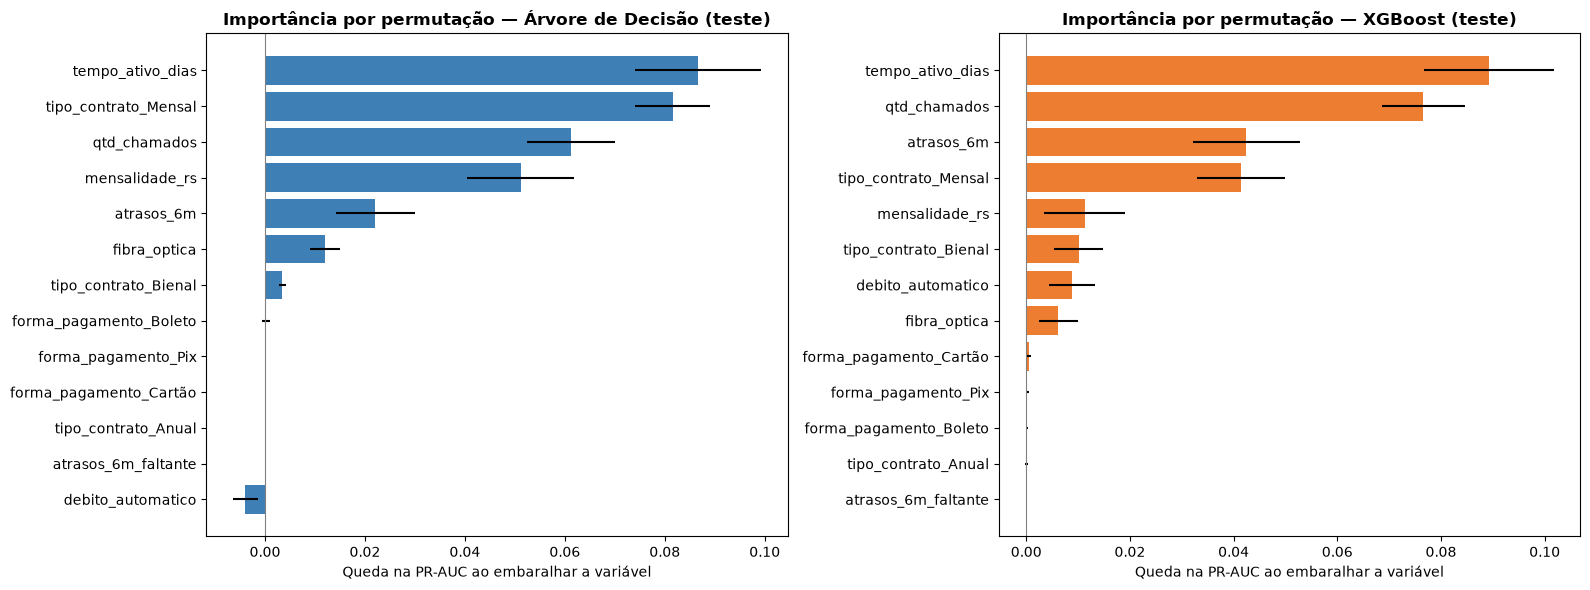

,AD (impureza),XGBoost (gain),Árvore de Decisão (permutação),XGBoost (permutação)
tempo_ativo_dias,0.2756,0.1029,0.0866,0.0892
qtd_chamados,0.1262,0.1032,0.0613,0.0766
atrasos_6m,0.1032,0.0884,0.0221,0.0424
tipo_contrato_Mensal,0.2920,0.3053,0.0816,0.0414
mensalidade_rs,0.1039,0.0401,0.0512,0.0112
tipo_contrato_Bienal,0.0152,0.0845,0.0035,0.0101
debito_automatico,0.0144,0.0548,-0.0039,0.0088
fibra_optica,0.0671,0.1333,0.0120,0.0062
forma_pagamento_Cartão,0.0000,0.0186,0.0000,0.0006
forma_pagamento_Pix,0.0000,0.0218,0.0000,0.0002


In [30]:
ganho_xgb = pd.Series(xgb_final.get_booster().get_score(importance_type='gain')).reindex(features).fillna(0)

importancias = pd.DataFrame({
    'AD (impureza)': pd.Series(ad_final.feature_importances_, index=features),
    'XGBoost (gain)': ganho_xgb / ganho_xgb.sum(),
})
permutacoes = {}
for nome, modelo in modelos_finais.items():
    r = permutation_importance(modelo, X_test, y_test, scoring='average_precision', n_repeats=20,
                               random_state=SEED, n_jobs=-1)
    permutacoes[nome] = pd.DataFrame({'media': r.importances_mean, 'desvio': r.importances_std}, index=features)
    importancias[f'{nome} (permutação)'] = r.importances_mean

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (nome, tabela) in zip(axes, permutacoes.items()):
    tabela = tabela.sort_values('media')
    ax.barh(tabela.index, tabela['media'], xerr=tabela['desvio'], color=cores_modelos[nome])
    ax.axvline(0, color='gray', linewidth=0.8)
    ax.set_title(f'Importância por permutação — {nome} (teste)', fontweight='bold')
    ax.set_xlabel('Queda na PR-AUC ao embaralhar a variável')
plt.tight_layout()
plt.show()

display(importancias.sort_values('XGBoost (permutação)', ascending=False).round(4))

**Conclusão:**

- Pela permutação, as variáveis que mais pesam nos dois modelos são **tempo_ativo_dias**, **qtd_chamados** e **tipo_contrato_Mensal**, seguidas de **atrasos_6m**. São as mesmas variáveis que a entrega 1 apontou como mais associadas ao churn (maiores KS e correlações).
- A importância nativa e a de permutação contam histórias diferentes. No XGBoost, `fibra_optica` e `tipo_contrato_Bienal` têm ganho alto, mas quase não fazem a PR-AUC cair quando são embaralhadas: a informação delas também está em outras variáveis (por exemplo, `tipo_contrato_Mensal` já separa contrato mensal de não mensal). Por isso a permutação é a referência para comparar os modelos.
- A árvore usa mais a mensalidade (0,051 contra 0,011 no XGBoost). Como a mensalidade tem relação fraca com o churn, esse uso pode ser parte do ruído que a árvore ajusta e o XGBoost não.
- As formas de pagamento e a flag de atraso faltante praticamente não contribuem em nenhum dos dois modelos.

### Leitura para o negócio

Com o limiar escolhido, a tabela mostra o que a área de retenção faria com cada modelo nos 1.497 clientes do teste.

In [31]:
linhas = {'Sem modelo (contatar todos)': {'Clientes contatados': len(y_test), 'Churns encontrados': int(y_test.sum()),
                                          'Churns perdidos': 0, 'Churns a cada 100 contatados': 100 * y_test.mean()}}
for nome, prob in prob_teste.items():
    pred = prob >= limiares[nome]
    encontrados = int((pred & (y_test == 1)).sum())
    linhas[nome] = {'Clientes contatados': int(pred.sum()), 'Churns encontrados': encontrados,
                    'Churns perdidos': int(y_test.sum()) - encontrados,
                    'Churns a cada 100 contatados': 100 * encontrados / pred.sum()}
negocio = pd.DataFrame(linhas).T
negocio['Lift'] = negocio['Churns a cada 100 contatados'] / (100 * y_test.mean())
display(negocio.round(2))

,Clientes contatados,Churns encontrados,Churns perdidos,Churns a cada 100 contatados,Lift
Sem modelo (contatar todos),1497.0,532.0,0.0,35.54,1.00
Árvore de Decisão,726.0,376.0,156.0,51.79,1.46
XGBoost,691.0,391.0,141.0,56.58,1.59


Sem modelo, para encontrar os 532 clientes que cancelariam seria preciso contatar todos os 1.497, e só 35,5 de cada 100 contatos seriam churns de verdade. Com o XGBoost, contatando 691 clientes (46% da base), a equipe encontra 391 churns (73,5%), e 56,6 de cada 100 contatos são clientes que iam cancelar: um lift de 1,59. A árvore encontra 15 churns a menos contatando 35 clientes a mais.

## Conclusões

- **Modelo recomendado: XGBoost** com árvores rasas (`max_depth=2`), taxa de aprendizado baixa, peso de classe e restrições monotônicas, usando o limiar de 0,493. No teste, ele encontra 73,5% dos clientes que cancelam com precision de 0,566 e ROC-AUC de 0,793.
- **A árvore de decisão continua útil para explicar o problema.** Ela fica um pouco atrás em desempenho (recall de 0,707 e precision de 0,518 no teste), mas gera regras diretas para a área de negócio. A regra mais forte é: contrato mensal, até 29 meses de casa e 3 ou mais chamados, com 74,5% de churn.
- **Escolhas de método que mudaram o resultado:**
  - otimizar a PR-AUC em vez do recall, que sozinho premia o modelo trivial;
  - dar o mesmo tratamento de peso de classe aos dois modelos;
  - escolher o limiar por uma meta de recall com probabilidades de validação cruzada, sem usar o teste.
- **Complexidade não trouxe ganho nesta base.** As melhores configurações são rasas nos dois algoritmos, e o XGBoost profundo (`max_depth=8`) ficou abaixo da própria árvore de decisão, com gap de 0,42 entre treino e validação.
- **Hipóteses testadas:** as variáveis criadas na entrega 1 (bins preditivos e Combo Risco Triplo) não melhoraram os modelos, porque as árvores já encontram esses cortes sozinhas. As restrições monotônicas ajudaram o XGBoost e prejudicaram a árvore.
- **Fatores de risco:** contrato mensal, pouco tempo de casa e muitos chamados de suporte são os principais sinais de cancelamento, seguidos pelos atrasos de pagamento. O tempo de casa é o principal fator de proteção.